# Body-force KM-PIKFNN: four cold starts, joint Levenberg–Marquardt

CUDA float64, 192 sources and 640 boundary points. Initial source scales: 1.15, 1.30, 1.40, 1.50. All coefficients start at zero; no warm start, no least-squares solution initialization, no coefficient-only stage. Boundary derivative enhancement has been removed.

Each adaptive LM step solves one damped linearization for coefficients and source position together. Coefficient Jacobians use the exact linear kernel matrix; the source Jacobian uses forward automatic differentiation. Jacobian columns are scaled, damping adapts to actual versus predicted loss reduction, and source motion per accepted step is limited to 0.03. The source stays outside the domain. At zero coefficients its initial Jacobian is necessarily zero; later joint steps can move it.

Fixed and adaptive runs share collocation points, initialization, regularization and LM budget. Four-panel histories, five-field full-grid relative L2 errors, elapsed times and existing PINN comparison are retained. No exact field data are used for training or model selection. Improvement over fixed sources is tested rather than assumed.

Outputs: literature23_joint_LM_results. CUDA is requested without silent CPU fallback. The kernel arithmetic is real float64; complex tensors only carry coordinates. GPU execution has not been verified in this CPU-only environment.


In [1]:
import numpy as np
import torch
from torch import nn
from scipy.linalg import qr, solve_triangular
import matplotlib.pyplot as plt
from pathlib import Path
import csv
import time
import json

# Physical fields: x=L*x*, u=U_ref*u*, sigma=Sigma_ref*sigma*.
cfg = dict(L=1.0, E_real=1.0e6, nu=1/3, U_ref=1.0e-4,
           n_source_per_side=48, n_boundary_per_side=160,
           alpha_initials=[1.15,1.30,1.40,1.50], alpha_min=1.03, alpha_max=2.20,
           warm_start=False, source_parameter_scale=1.0,
           regularization=1e-14, lm_steps=80, lm_initial_damping=1e-3,
           lm_min_damping=1e-10, lm_max_damping=1e12, lm_max_trials=10,
           lm_source_step_limit=0.03, lm_tol_loss=1e-12, lm_tol_step=1e-10,
           print_every=5, nx_plot=101, legend_fontsize=15, label_fontsize=14,
           device='cuda', cuda_fallback_to_cpu=False, save_outputs=True, output_dir='literature23_joint_LM_results',
           pinn_output_dir='literature23_pinn_results')
dtype = torch.float64
# Windows NVRTC may not find its builtins DLL even when a GPU is visible.
# Keep directory handles alive for the lifetime of the notebook kernel.
import os
import sys
_dll_directory_handles = []
if os.name == 'nt' and hasattr(os, 'add_dll_directory'):
    cuda_version = torch.version.cuda or ''
    suffix = cuda_version.replace('.', '')
    builtin_name = f'nvrtc-builtins64_{suffix}.dll'
    candidates = [Path(torch.__file__).resolve().parent/'lib',
                  Path(sys.prefix)/'Library'/'bin']
    if os.environ.get('CUDA_PATH'):
        candidates.append(Path(os.environ['CUDA_PATH'])/'bin')
    for directory in candidates:
        if (directory/builtin_name).is_file():
            _dll_directory_handles.append(os.add_dll_directory(str(directory)))

def _cuda_complex_probe(selected_device):
    # Training uses real float64 tensors only; avoid complex CUDA Jiterator kernels.
    x=torch.linspace(.2,1.2,128,dtype=torch.float64,device=selected_device,requires_grad=True)
    y=.3*x+.1
    r2=x*x+y*y
    ir,ii=x/r2,-y/r2
    lr,li=.5*torch.log(r2),torch.atan2(y,x)
    value=(lr+li+ir+ii+ir*ir-ii*ii).square().sum()
    value.backward();torch.cuda.synchronize(selected_device)

def select_device(requested='auto', fallback=True, probe=None):
    selected = torch.device(('cuda' if torch.cuda.is_available() else 'cpu')
                            if requested == 'auto' else requested)
    if selected.type == 'cuda':
        try:
            (_cuda_complex_probe if probe is None else probe)(selected)
        except (RuntimeError, OSError, AssertionError) as error:
            if not fallback:
                raise
            # Do not print the thousands of lines of generated CUDA source.
            lines = str(error).strip().splitlines()
            reason = next((line.strip() for line in lines
                           if 'nvrtc:' in line or 'failed to open' in line),
                          lines[-1] if lines else type(error).__name__)
            print('CUDA float64-operation check failed:', reason)
            print('Switching this run to CPU. Set cfg["device"]="cpu" to skip the CUDA check.')
            selected = torch.device('cpu')
    return selected

if cfg['warm_start']:
    raise ValueError('This notebook uses zero-coefficient cold starts. Keep warm_start=False.')
device = select_device(cfg['device'], cfg['cuda_fallback_to_cpu'])
if device.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
np.random.seed(42)
torch.manual_seed(42)
L, E_real, nu, U_ref = (cfg[k] for k in ('L', 'E_real', 'nu', 'U_ref'))
# The literature parameters are nondimensional: lambda=1, mu=0.5.
# These imply E*=4/3 and nu=1/3 in plane strain.
if not np.isclose(nu, 1/3):
    raise ValueError('Use nu=1/3 to reproduce literature [23].')
mu, lam, kappa, Q = 0.5, 1.0, 3-4*nu, 4.0
E_star = 4/3
Sigma_ref = E_real*U_ref/(E_star*L)
F_ref = Sigma_ref/L
print('Device:', device, '| float64 | plane strain | lambda*=1, mu*=0.5, Q=4')
print('Physical scales: displacement=', U_ref, 'm; stress=', Sigma_ref, 'Pa')


Device: cuda | float64 | plane strain | lambda*=1, mu*=0.5, Q=4
Physical scales: displacement= 0.0001 m; stress= 75.0 Pa


## 场表达、边界损失及源点与系数的联合优化


In [2]:
def tensor(x):
    is_complex = x.is_complex() if isinstance(x, torch.Tensor) else np.iscomplexobj(x)
    return torch.as_tensor(x, dtype=torch.complex128 if is_complex else dtype, device=device)

def exact_fields(z):
    # Reference fields from the published displacement solution.
    x, y = z.real, z.imag
    px, py = torch.pi*x, torch.pi*y
    ux = torch.cos(2*px)*torch.sin(py)
    uy = (Q/4)*torch.sin(px)*y**4
    ex = -2*torch.pi*torch.sin(2*px)*torch.sin(py)
    ey = Q*torch.sin(px)*y**3
    shear = torch.pi*torch.cos(2*px)*torch.cos(py)+(Q*torch.pi/4)*torch.cos(px)*y**4
    return torch.stack((ux,uy,(lam+2*mu)*ex+lam*ey,
                        lam*ex+(lam+2*mu)*ey,mu*shear),dim=-1)

def particular_fields(z):
    # Explicit particular solution chosen from the forcing, with a nonzero
    # homogeneous correction. Do not return the complete exact solution here.
    x, y = z.real, z.imag
    k, d = 2*torch.pi, 1/(kappa-1)
    kt = k*(y-0.5)
    ch, sh = torch.cosh(kt), torch.sinh(kt)
    U = ch+d*kt*sh
    V = d*(kt*ch-sh)
    Up = k*sh+d*k*(sh+kt*ch)
    Vp = d*k*kt*sh
    cx, sx = torch.cos(k*x), torch.sin(k*x)
    ux = cx*(torch.sin(torch.pi*y)-U)
    uy = (Q/4)*torch.sin(torch.pi*x)*y**4-sx*V
    ex = -k*sx*(torch.sin(torch.pi*y)-U)
    ey = Q*torch.sin(torch.pi*x)*y**3-sx*Vp
    shear = cx*(torch.pi*torch.cos(torch.pi*y)-Up-k*V)+(Q*torch.pi/4)*torch.cos(torch.pi*x)*y**4
    return torch.stack((ux,uy,(lam+2*mu)*ex+lam*ey,
                        lam*ex+(lam+2*mu)*ey,mu*shear),dim=-1)

def body_force_fields(z):
    # Sign convention: div(sigma)+f=0. Literature formula, not a fitted force.
    x, y = z.real, z.imag
    px, py = torch.pi*x, torch.pi*y
    fx = ((4*lam+9*mu)*torch.pi**2*torch.cos(2*px)*torch.sin(py)
          -(lam+mu)*torch.pi*Q*y**3*torch.cos(px))
    fy = (2*(lam+mu)*torch.pi**2*torch.sin(2*px)*torch.cos(py)
          -3*(lam+2*mu)*Q*y**2*torch.sin(px)
          +(mu*torch.pi**2*Q/4)*y**4*torch.sin(px))
    return torch.stack((fx,fy),dim=-1)

def boundary_columns(key):
    # bottom: ux,uy; top: ux,syy; sides: uy,sxx. No extra shear condition.
    return {'bottom':(0,1),'top':(0,3),'left':(1,2),'right':(1,2)}[key]

def prescribed_boundary(key,z):
    out = torch.zeros((len(z),2),dtype=dtype,device=device)
    if key == 'top':
        out[:,1] = (lam+2*mu)*Q*torch.sin(torch.pi*z.real)
    return out

def von_mises(q):
    sx, sy, t = q[..., 2], q[..., 3], q[..., 4]
    sz = nu*(sx+sy)
    return torch.sqrt(torch.clamp(((sx-sy)**2+(sy-sz)**2+(sz-sx)**2)/2+3*t*t, min=0))

def boundary_points(n, held_out=False):
    # Training and independent validation points do not coincide.
    t = (np.arange(n)+(0.5 if held_out else 0.25))/n
    return {key: tensor(z) for key, z in dict(bottom=t+0j, top=t+1j,
            left=1j*t, right=1+1j*t).items()}

train_points = boundary_points(cfg['n_boundary_per_side'])
check_points = boundary_points(2*cfg['n_boundary_per_side']+1, True)

def boundary_targets(points):
    # Only the published boundary conditions enter training.
    # The full interior exact solution is never used to construct this target.
    return {key:(prescribed_boundary(key,z)-particular_fields(z)[:,list(boundary_columns(key))]).detach()
            for key,z in points.items()}

train_targets, check_targets = boundary_targets(train_points), boundary_targets(check_points)

class KMBodyForceNet(nn.Module):
    def __init__(self, alpha0, adaptive=True):
        super().__init__()
        n = cfg['n_source_per_side']
        t = np.linspace(-0.5, 0.5, n+2)[1:-1]
        base = tensor(np.concatenate((t-0.5j, 0.5+1j*t, t[::-1]+0.5j, -0.5+1j*t[::-1])))
        self.register_buffer('base', base)
        self.register_buffer('branch', torch.atan2(-base.imag,-base.real))
        self.ns = len(base)
        self.register_buffer('coefficient_map', torch.eye(2*self.ns+8,dtype=dtype,device=device))
        self.register_buffer('column_scale', torch.ones(2*self.ns+8, dtype=dtype, device=device))
        fraction = (alpha0-cfg['alpha_min'])/(cfg['alpha_max']-cfg['alpha_min'])
        self.eta = nn.Parameter(tensor(cfg['source_parameter_scale']*np.log(fraction/(1-fraction))),
                                requires_grad=adaptive)
        self.theta = nn.Parameter(torch.zeros(2*self.ns+8, dtype=dtype, device=device))

    def alpha(self,eta=None):
        return cfg['alpha_min']+(cfg['alpha_max']-cfg['alpha_min'])*torch.sigmoid((self.eta if eta is None else eta)/cfg['source_parameter_scale'])

    def source_coordinates(self,eta=None):
        alpha=self.alpha(eta)
        return .5+alpha*self.base.real,.5+alpha*self.base.imag

    def sources(self):
        # Complex coordinates are only an output container for plotting/export.
        sr,si=self.source_coordinates()
        return torch.complex(sr,si)

    def fields(self,z,raw_coefficients=None,source_parameter=None):
        # Exact real/imaginary expansion of the same KM complex point-force kernels.
        # No complex elementary operations or complex autograd occur in training.
        c=self.raw_coefficients() if raw_coefficients is None else raw_coefficients
        x,y=z.real,z.imag
        sr,si=self.source_coordinates(source_parameter)
        dx=x[:,None]-sr[None,:]
        dy=y[:,None]-si[None,:]
        r2=dx*dx+dy*dy
        ir,ii=dx/r2,-dy/r2
        i2r,i2i=ir*ir-ii*ii,2*ir*ii
        cs,sn=torch.cos(self.branch),torch.sin(self.branch)
        lr=.5*torch.log(r2)
        li=torch.atan2(dy*cs-dx*sn,dx*cs+dy*sn)+self.branch
        pr,pi=c[:self.ns]/np.sqrt(self.ns),c[self.ns:2*self.ns]/np.sqrt(self.ns)
        csr,csi=(sr[:,None],si[:,None]) if c.ndim==2 else (sr,si)
        cr,ci=pr*csr+pi*csi,pi*csr-pr*csi  # P times conjugate(source)
        cf=1/(2*np.pi*(kappa+1))
        phr=-cf*(lr@pr-li@pi)
        phi=-cf*(lr@pi+li@pr)
        dphr=-cf*(ir@pr-ii@pi)
        dphi=-cf*(ir@pi+ii@pr)
        ddphr=cf*(i2r@pr-i2i@pi)
        ddphi=cf*(i2r@pi+i2i@pr)
        psr=cf*(kappa*(lr@pr+li@pi)+ir@cr-ii@ci)
        psi=cf*(kappa*(li@pr-lr@pi)+ir@ci+ii@cr)
        dpsr=cf*(kappa*(ir@pr+ii@pi)-i2r@cr+i2i@ci)
        dpsi=cf*(kappa*(ii@pr-ir@pi)-i2r@ci-i2i@cr)
        if c.ndim==2: x,y=x[:,None],y[:,None]
        affine=c[2*self.ns:].reshape((4,2)+tuple(c.shape[1:]))
        phr=phr+affine[0,0]+affine[1,0]*x-affine[1,1]*y
        phi=phi+affine[0,1]+affine[1,0]*y+affine[1,1]*x
        psr=psr+affine[2,0]+affine[3,0]*x-affine[3,1]*y
        psi=psi+affine[2,1]+affine[3,0]*y+affine[3,1]*x
        dphr,dphi=dphr+affine[1,0],dphi+affine[1,1]
        dpsr,dpsi=dpsr+affine[3,0],dpsi+affine[3,1]
        ux=(kappa*phr-x*dphr-y*dphi-psr)/(2*mu)
        uy=(kappa*phi-y*dphr+x*dphi+psi)/(2*mu)
        devr=x*ddphr+y*ddphi+dpsr
        devi=x*ddphi-y*ddphr+dpsi
        return torch.stack((ux,uy,2*dphr-devr,2*dphr+devr,devi),dim=-1)

    def raw_coefficients(self):
        return (self.coefficient_map@self.theta)/self.column_scale

    def total_fields(self, z):
        return self.fields(z)+particular_fields(z)

def residuals(model, points, targets, coefficients=None):
    items = []
    for key, z in points.items():
        columns = boundary_columns(key)
        items.append((model.fields(z, coefficients)[:, list(columns)]-targets[key]).reshape(-1)
                     /np.sqrt(len(z)))
    return torch.cat(items)

def edge_losses(model, points=train_points, targets=train_targets):
    r = residuals(model, points, targets)
    # Each edge loss is mean squared Euclidean residual of its two components.
    lengths = [2*len(z) for z in points.values()]
    return {key: chunk.square().sum() for key, chunk in zip(points, r.split(lengths))}

def boundary_loss(model, points=train_points, targets=train_targets):
    return residuals(model, points, targets).square().sum()

def boundary_matrix(model,points):
    # Linear coefficient Jacobian, assembled in one batch per edge.
    identity=torch.eye(2*model.ns+8,dtype=dtype,device=device)
    matrices=[]
    for key,z in points.items():
        basis=model.fields(z,identity)[:,:,list(boundary_columns(key))]
        matrices.append(basis.permute(0,2,1).reshape(2*len(z),-1)/np.sqrt(len(z)))
    return torch.cat(matrices)

def initialize(model):
    t0=time.perf_counter()
    with torch.no_grad():
        matrix=boundary_matrix(model,train_points)
        model.column_scale.copy_(torch.linalg.vector_norm(matrix,dim=0).clamp_min(1e-12))
        model.qr_rank=None
        assert torch.count_nonzero(model.raw_coefficients()).item()==0
    if device.type=='cuda':torch.cuda.synchronize()
    print('  Cold start: zero coefficients; column scaling only; no solution initialization')
    return time.perf_counter()-t0

def lm_residual(model,eta=None):
    pieces=[]
    for key,z in train_points.items():
        f=model.fields(z,source_parameter=eta)[:,list(boundary_columns(key))]
        pieces.append((f-train_targets[key]).reshape(-1)/np.sqrt(len(z)))
    pieces.append(np.sqrt(cfg['regularization']/model.theta.numel())*model.theta)
    return torch.cat(pieces)

def objective(model):
    return lm_residual(model).square().sum()

def lm_jacobian(model,adaptive):
    A=boundary_matrix(model,train_points)/model.column_scale[None,:]
    nc=model.theta.numel()
    if adaptive:
        # Exact forward AD for the scalar source parameter, not finite differences.
        _,j_eta=torch.func.jvp(lambda eta:lm_residual(model,eta),
                               (model.eta.detach(),),(torch.ones_like(model.eta),))
        A=torch.cat((A,j_eta[:A.shape[0],None]),dim=1)
    reg=torch.zeros((nc,A.shape[1]),dtype=dtype,device=device)
    reg[:,:nc]=np.sqrt(cfg['regularization']/nc)*torch.eye(nc,dtype=dtype,device=device)
    return torch.cat((A,reg))

def train_one(alpha0,adaptive=True):
    if device.type=='cuda':torch.cuda.synchronize()
    t0=time.perf_counter();model=KMBodyForceNet(alpha0,adaptive).to(device)
    init_time=initialize(model);history=[];evaluations=0
    damping=cfg['lm_initial_damping']
    def record(epoch,accepted=False,rho=float('nan')):
        with torch.no_grad():
            edges=edge_losses(model);q=model.total_fields(monitor_z)
            row=dict(iteration=epoch,closure_evaluations=evaluations,alpha=model.alpha().item(),
                     stage='joint LM' if adaptive else 'fixed-source LM',
                     boundary_loss=sum(v.item() for v in edges.values()),objective=objective(model).item(),
                     held_out_loss=boundary_loss(model,check_points,check_targets).item(),
                     displacement_L2=(torch.linalg.vector_norm(q[:,:2]-monitor_ref[:,:2])/torch.linalg.vector_norm(monitor_ref[:,:2])).item(),
                     stress_L2=(torch.linalg.vector_norm(q[:,2:]-monitor_ref[:,2:])/torch.linalg.vector_norm(monitor_ref[:,2:])).item(),
                     damping=damping,accepted=accepted,reduction_ratio=rho)
            row.update({f'loss_{k}':v.item() for k,v in edges.items()});history.append(row)
        return row
    record(0)
    print(f"{'Adaptive' if adaptive else 'Fixed'} LM: alpha0={alpha0:.2f}, Ns={model.ns}")
    for epoch in range(1,cfg['lm_steps']+1):
        with torch.no_grad():
            r=lm_residual(model);evaluations+=1;value=r.square().sum()
            J=lm_jacobian(model,adaptive)
            # Scale both coefficient and source columns in the same linearized solve.
            scales=torch.linalg.vector_norm(J,dim=0).clamp_min(1e-12)
            K=J/scales[None,:];G=K.T@K;g=K.T@r
            old_theta=model.theta.detach().clone();old_eta=model.eta.detach().clone()
            old_alpha=model.alpha().item();accepted=False;rho=float('nan');step_norm=float('inf')
            for trial in range(cfg['lm_max_trials']):
                H=G+damping*torch.eye(G.shape[0],dtype=dtype,device=device)
                chol,info=torch.linalg.cholesky_ex(H)
                if info.item()!=0:
                    damping=min(damping*10,cfg['lm_max_damping']);continue
                step=torch.cholesky_solve((-g)[:,None],chol).squeeze(1)/scales
                if adaptive:
                    proposed=model.alpha(old_eta+step[-1]).item()
                    change=proposed-old_alpha;limit=cfg['lm_source_step_limit']
                    if abs(change)>limit:
                        target=old_alpha+np.sign(change)*limit
                        fraction=(target-cfg['alpha_min'])/(cfg['alpha_max']-cfg['alpha_min'])
                        target_eta=cfg['source_parameter_scale']*np.log(fraction/(1-fraction))
                        factor=min(1.,abs((target_eta-old_eta.item())/step[-1].item()))
                        step=step*factor  # Keep a joint step, not alternating updates.
                nc=model.theta.numel();model.theta.copy_(old_theta+step[:nc])
                if adaptive:model.eta.copy_(old_eta+step[-1])
                new_value=objective(model);evaluations+=1
                predicted=value-(r+J@step).square().sum()
                rho=((value-new_value)/predicted).item() if predicted.item()>0 else -1.
                if torch.isfinite(new_value) and new_value<value and rho>1e-4:
                    accepted=True;step_norm=torch.linalg.vector_norm(scales*step).item()
                    damping=max(cfg['lm_min_damping'],damping*(.3 if rho>.75 else 1.))
                    break
                model.theta.copy_(old_theta);model.eta.copy_(old_eta)
                damping=min(damping*10,cfg['lm_max_damping'])
        row=record(epoch,accepted,rho)
        if epoch==1 or epoch%cfg['print_every']==0 or epoch==cfg['lm_steps']:
            print(f"  LM {epoch:3d}: alpha={row['alpha']:.8f} (delta={row['alpha']-alpha0:+.3e}), "
                  f"boundary={row['boundary_loss']:.3e}, held-out={row['held_out_loss']:.3e}, "
                  f"L2(u)={row['displacement_L2']:.3e}, L2(stress)={row['stress_L2']:.3e}, "
                  f"accepted={accepted}, damping={damping:.2e}")
        if row['objective']<cfg['lm_tol_loss'] or (accepted and step_norm<cfg['lm_tol_step']):break
        if not accepted and damping>=cfg['lm_max_damping']:break
    if device.type=='cuda':torch.cuda.synchronize()
    return dict(model=model,history=history,alpha0=alpha0,adaptive=adaptive,
                parameter_count=sum(p.numel() for p in model.parameters() if p.requires_grad),
                elapsed=time.perf_counter()-t0,initialization_time=init_time,
                check_loss=boundary_loss(model,check_points,check_targets).item())

t = np.linspace(0.02, 0.98, 31)
mx, my = np.meshgrid(t, t)
monitor_z = tensor((mx+1j*my).ravel())
monitor_ref = exact_fields(monitor_z).detach()
# Paired experiments: only source-position trainability changes.
fixed_runs, runs = [], []
for alpha0 in cfg['alpha_initials']:
    fixed_runs.append(train_one(alpha0, adaptive=False))
    runs.append(train_one(alpha0, adaptive=True))
all_runs = [run for pair in zip(fixed_runs, runs) for run in pair]

# Choose by independent boundary residual, NEVER by interior reference error.
best_run = min(runs, key=lambda r: r['check_loss'])
model = best_run['model']
print('Selected by independent boundary loss:', best_run['alpha0'],
      '->', model.alpha().item(), '| total elapsed includes initialization:', best_run['elapsed'])


  Cold start: zero coefficients; column scaling only; no solution initialization
Fixed LM: alpha0=1.15, Ns=192
  LM   1: alpha=1.15000000 (delta=+0.000e+00), boundary=9.132e-02, held-out=9.460e-02, L2(u)=1.250e-01, L2(stress)=1.325e-01, accepted=True, damping=3.00e-04
  LM   5: alpha=1.15000000 (delta=+0.000e+00), boundary=5.513e-05, held-out=7.226e-05, L2(u)=7.290e-04, L2(stress)=2.813e-03, accepted=True, damping=2.43e-06
  LM  10: alpha=1.15000000 (delta=+0.000e+00), boundary=7.738e-08, held-out=2.526e-07, L2(u)=1.892e-05, L2(stress)=8.895e-05, accepted=True, damping=5.90e-09
  LM  15: alpha=1.15000000 (delta=+0.000e+00), boundary=1.702e-09, held-out=1.397e-08, L2(u)=1.321e-06, L2(stress)=7.588e-06, accepted=True, damping=1.00e-10
  LM  20: alpha=1.15000000 (delta=+0.000e+00), boundary=1.194e-09, held-out=5.874e-09, L2(u)=8.103e-07, L2(stress)=4.987e-06, accepted=True, damping=1.00e-10
  LM  25: alpha=1.15000000 (delta=+0.000e+00), boundary=1.041e-09, held-out=2.968e-09, L2(u)=5.723e

## 独立验证及五个场变量的相对 L2 误差
解析解、特解、总预测场均检查平衡方程；解析解检查原文边界条件。内部验证点不进入训练。


In [3]:

pos = tensor(np.random.uniform(0.1, 0.9, (30, 2))).requires_grad_(True)
zp = torch.complex(pos[:, 0], pos[:, 1])
qref = exact_fields(zp)
gr = [torch.autograd.grad(qref[:, i].sum(), pos, retain_graph=True)[0] for i in (2,3,4)]
fr = body_force_fields(zp)
eq_ref = torch.stack((gr[0][:, 0]+gr[2][:, 1]+fr[:, 0],
                      gr[2][:, 0]+gr[1][:, 1]+fr[:, 1]), dim=-1)
print('Exact-reference equilibrium max residual (normalized):', eq_ref.abs().max().item())
assert eq_ref.abs().max().item() < 1e-10
qp = particular_fields(zp)
gp = [torch.autograd.grad(qp[:,i].sum(),pos,retain_graph=True)[0] for i in (2,3,4)]
eqp = torch.stack((gp[0][:,0]+gp[2][:,1]+fr[:,0],gp[2][:,0]+gp[1][:,1]+fr[:,1]),dim=-1)
print('Particular-solution equilibrium max residual:',eqp.abs().max().item())
assert eqp.abs().max().item()<1e-9
for edge,z in check_points.items():
    bc_error=(exact_fields(z)[:,list(boundary_columns(edge))]-prescribed_boundary(edge,z)).abs().max().item()
    assert bc_error<1e-10, f'Published boundary check failed on {edge}'
# Independent interior verification (diagnostic only, not a training residual).
xy = tensor(np.random.uniform(0.1, 0.9, (30, 2))).requires_grad_(True)
z_test = torch.complex(xy[:, 0], xy[:, 1])
q_test = model.total_fields(z_test)
def spatial_gradient(value):
    return torch.autograd.grad(value.sum(), xy, create_graph=True)[0]
sxg, syg, tg = (spatial_gradient(q_test[:, i]) for i in (2, 3, 4))
f_test = body_force_fields(z_test)
eq = torch.stack((sxg[:, 0]+tg[:, 1]+f_test[:, 0],
                  tg[:, 0]+syg[:, 1]+f_test[:, 1]), dim=-1)
ug, vg = spatial_gradient(q_test[:, 0]), spatial_gradient(q_test[:, 1])
sx_hooke = (lam+2*mu)*ug[:, 0]+lam*vg[:, 1]
sy_hooke = lam*ug[:, 0]+(lam+2*mu)*vg[:, 1]
t_hooke = mu*(ug[:, 1]+vg[:, 0])
constitutive = q_test[:, 2:]-torch.stack((sx_hooke, sy_hooke, t_hooke), dim=-1)
equilibrium_max = eq.abs().max().item()
constitutive_max = constitutive.abs().max().item()
print(f'Independent equilibrium max residual (normalized): {equilibrium_max:.3e}')
print(f'Independent constitutive max residual (normalized): {constitutive_max:.3e}')
assert equilibrium_max < 1e-8 and constitutive_max < 1e-8, 'Physical identity check failed'

def batched_predict(z, batch_size=2048):
    with torch.no_grad():
        return torch.cat([model.total_fields(c) for c in z.split(batch_size)]).cpu().numpy()

axis = np.linspace(0, 1, cfg['nx_plot'])
X, Y = np.meshgrid(axis, axis)
plot_z = tensor((X+1j*Y).ravel())
prediction = batched_predict(plot_z)
with torch.no_grad():
    reference = exact_fields(plot_z).cpu().numpy()
physical_scales = np.array([U_ref,U_ref,Sigma_ref,Sigma_ref,Sigma_ref])
prediction_real,reference_real = prediction*physical_scales,reference*physical_scales
quantities=('ux','uy','sxx','syy','sxy')
labels=(r'$u_x$ (m)',r'$u_y$ (m)',r'$\sigma_{xx}$ (Pa)',r'$\sigma_{yy}$ (Pa)',r'$\sigma_{xy}$ (Pa)')
error_table = []
for i, name in enumerate(quantities):
    relative = np.linalg.norm(prediction[:, i]-reference[:, i])/np.linalg.norm(reference[:, i])
    maximum = np.max(abs(prediction[:, i]-reference[:, i]))/np.max(abs(reference[:, i]))
    error_table.append(dict(quantity=name, relative_L2=relative, max_normalized_error=maximum))
    print(f'{name:10s}: relative L2={relative:.6e}, max normalized error={maximum:.6e}')
print('Each held-out boundary loss:', {k: v.item() for k, v in edge_losses(model, check_points, check_targets).items()})


# Componentwise full-grid relative L2 errors, identical points for every run.
per_run_metrics = []
for run in all_runs:
    with torch.no_grad():
        predicted = torch.cat([run['model'].total_fields(chunk)
                               for chunk in plot_z.split(2048)]).cpu().numpy()
    component_errors = np.linalg.norm(predicted-reference, axis=0)/np.linalg.norm(reference, axis=0)
    row = dict(method='Adaptive KM-PIKFNN' if run['adaptive'] else 'Fixed KM-PIKFNN',
               alpha_initial=run['alpha0'], alpha_final=run['model'].alpha().item(),
               **{f'L2_{q}':float(e) for q,e in zip(quantities,component_errors)},
               time_seconds=run['elapsed'], initialization_seconds=run['initialization_time'],
               boundary_loss=boundary_loss(run['model']).item(), held_out_loss=run['check_loss'],
               parameter_count=run['parameter_count'], qr_rank=run['model'].qr_rank, n_sources=run['model'].ns,
               n_boundary=4*cfg['n_boundary_per_side'], n_interior=0, device=str(device),
               warm_start=str(cfg['warm_start']))
    per_run_metrics.append(row)
    print(row['method'], f"alpha0={row['alpha_initial']:.2f}, alpha_f={row['alpha_final']:.6f}",
          'L2:', ' '.join(f"{q}={row['L2_'+q]:.3e}" for q in quantities),
          f"time={row['time_seconds']:.2f} s (includes initialization)")

# Direct pairwise accuracy assessment; reference errors remain diagnostics only.
paired_error_ratios=[]
for fixed,adaptive in zip(per_run_metrics[::2],per_run_metrics[1::2]):
    row=dict(alpha_initial=fixed['alpha_initial'],alpha_final=adaptive['alpha_final'])
    for q in quantities:row['adaptive_over_fixed_'+q]=adaptive['L2_'+q]/max(fixed['L2_'+q],1e-30)
    row['all_five_improved']=all(row['adaptive_over_fixed_'+q]<1 for q in quantities)
    paired_error_ratios.append(row)
    print('Adaptive/fixed error ratios (<1 improves):',row)

if cfg['save_outputs']:
    folder=Path(cfg['output_dir']);folder.mkdir(parents=True,exist_ok=True)
    def export_csv(name, rows):
        with (folder/name).open('w',newline='',encoding='utf-8-sig') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    export_csv('per_run_metrics.csv',per_run_metrics)
    export_csv('paired_error_ratios.csv',paired_error_ratios)
    search_costs = [dict(method=name, runs=len(group),
                        total_solver_seconds=sum(r['elapsed'] for r in group),
                        selected_alpha_initial=min(group,key=lambda r:r['check_loss'])['alpha0'])
                    for name,group in [('Fixed KM-PIKFNN',fixed_runs),('Adaptive KM-PIKFNN',runs)]]
    export_csv('search_costs.csv',search_costs)
    (folder/'experiment_settings.json').write_text(json.dumps(dict(settings=cfg, device=str(device),
        error_definition='componentwise norm(prediction-reference)/norm(reference) on nx_plot^2 grid',
        timing_scope='Per run: model initialization, column assembly, column normalization, joint or fixed-source LM training, in-training diagnostics; excludes final field evaluation, export, plotting',
        pairing='Fixed and adaptive have identical initial source alpha, cold start, boundary points, regularization, and LM budgets',
        selection='independent boundary residual, never reference error'),indent=2),encoding='utf-8')
    for run in all_runs:
        kind='adaptive' if run['adaptive'] else 'fixed'
        export_csv(f"history_{kind}_alpha{run['alpha0']:.2f}.csv",run['history'])


Exact-reference equilibrium max residual (normalized): 1.4210854715202004e-14
Particular-solution equilibrium max residual: 3.268496584496461e-13
Independent equilibrium max residual (normalized): 4.263e-13
Independent constitutive max residual (normalized): 1.954e-13
ux        : relative L2=8.817153e-07, max normalized error=9.042035e-06
uy        : relative L2=2.218958e-06, max normalized error=1.224235e-05
sxx       : relative L2=5.980305e-06, max normalized error=5.707441e-05
syy       : relative L2=2.022347e-05, max normalized error=4.808223e-04
sxy       : relative L2=6.164644e-05, max normalized error=8.806094e-04
Each held-out boundary loss: {'bottom': 1.4317692501015753e-11, 'top': 2.3643338105160806e-11, 'left': 7.684843166340205e-12, 'right': 6.7060138633745e-12}
Fixed KM-PIKFNN alpha0=1.15, alpha_f=1.150000 L2: ux=6.269e-07 uy=1.604e-06 sxx=7.997e-06 syy=2.344e-05 sxy=5.989e-05 time=4.07 s (includes initialization)
Adaptive KM-PIKFNN alpha0=1.15, alpha_f=1.154034 L2: ux=1.9

## 解析解与 KM-PIKFNN 云图、源点分布、优化曲线
分别生成十张单独云图。同一场变量两种解的色标一致；颜色条为平端并与云图等高。默认保存 PNG、误差表、每组训练历史与 NPZ 场数据。


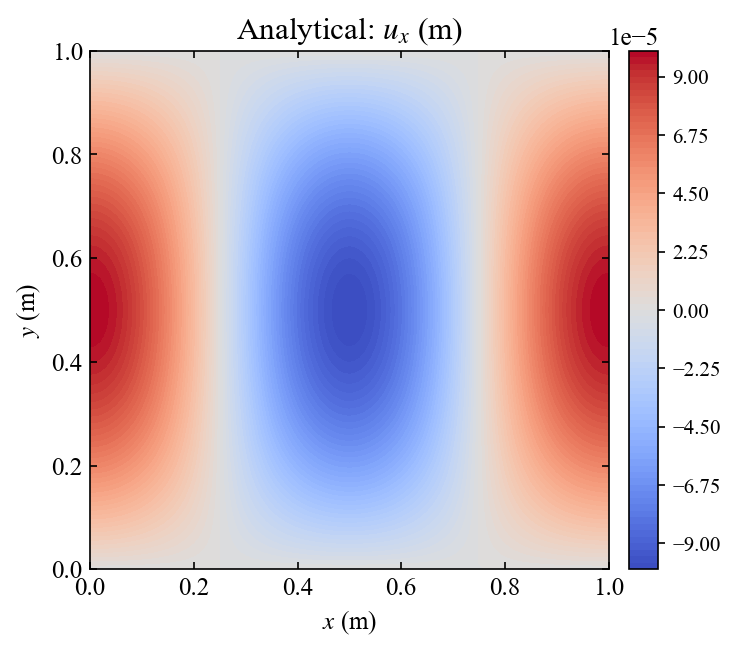

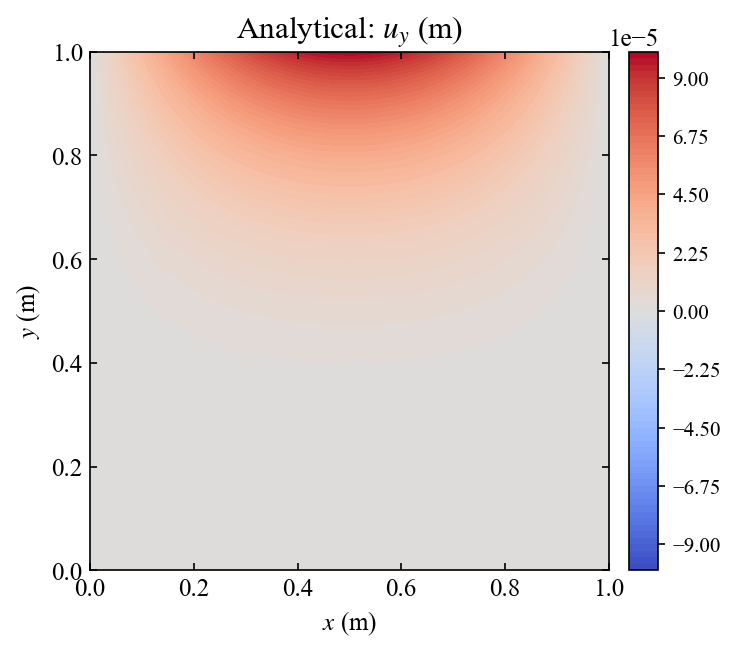

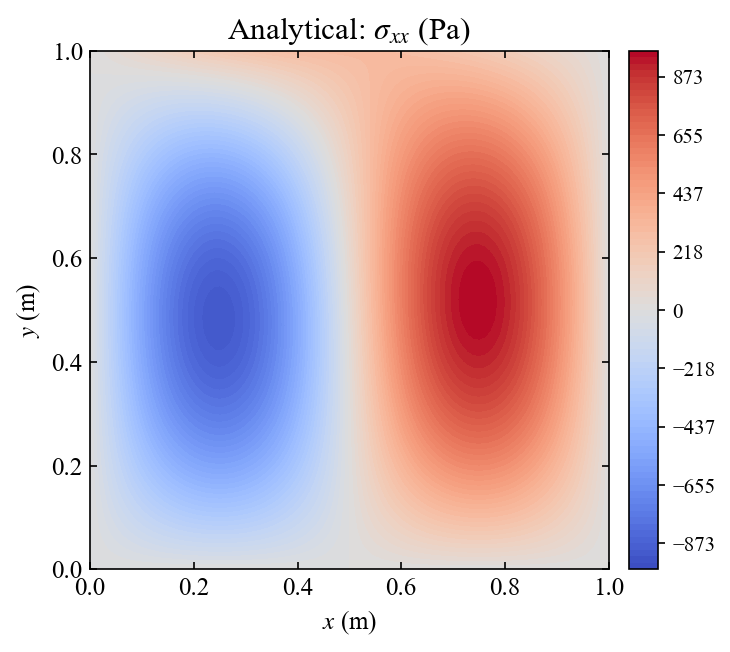

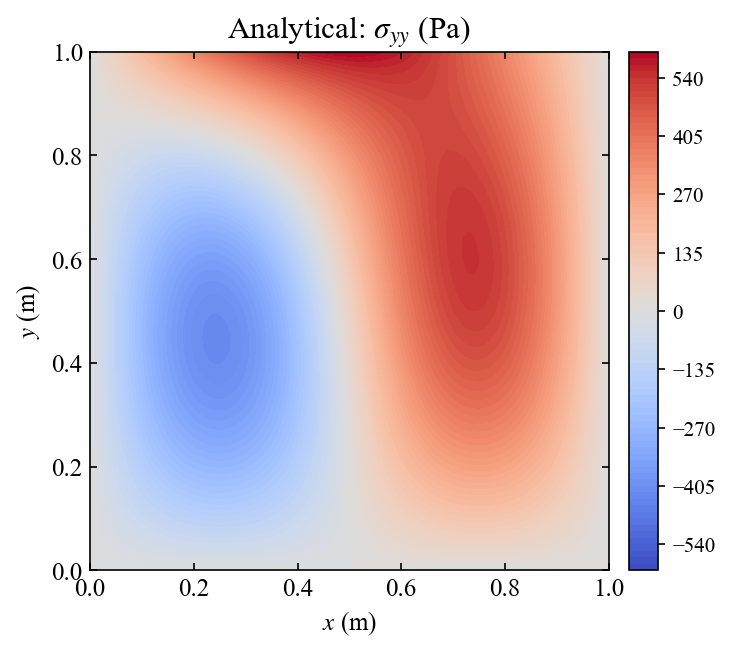

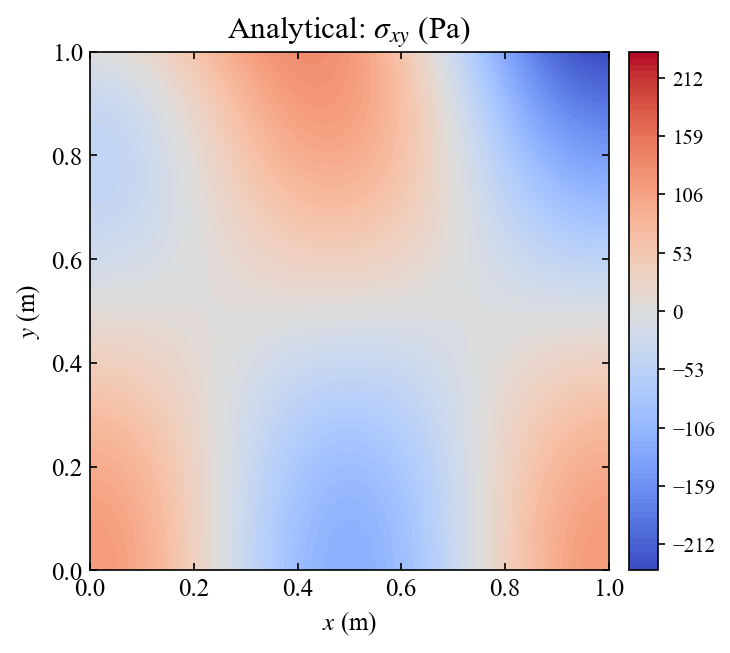

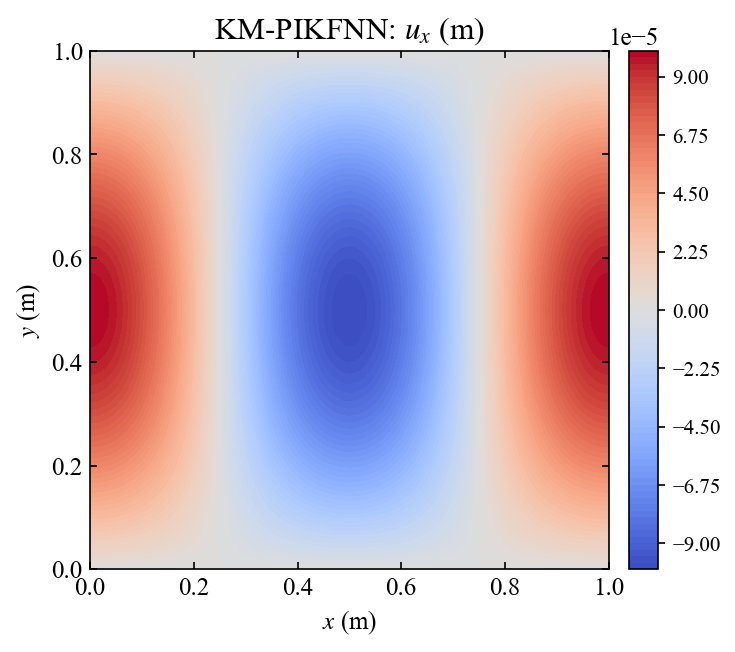

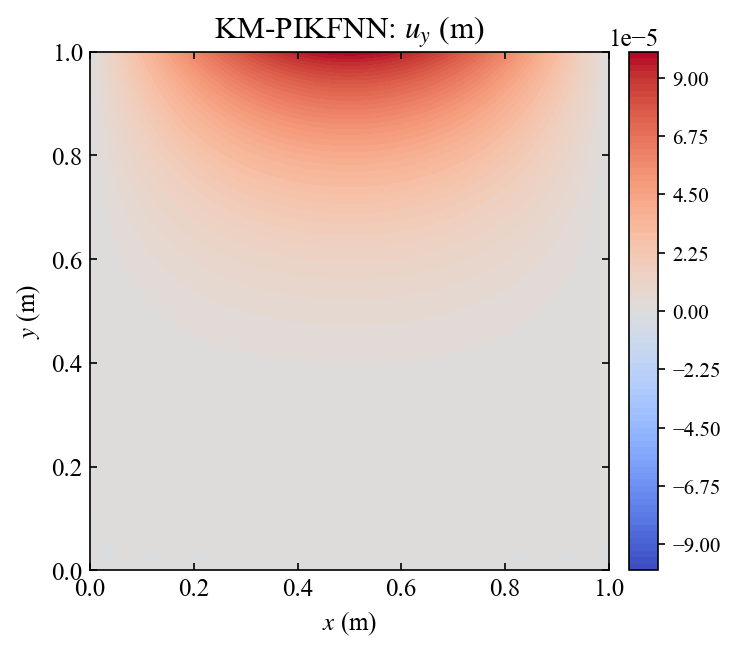

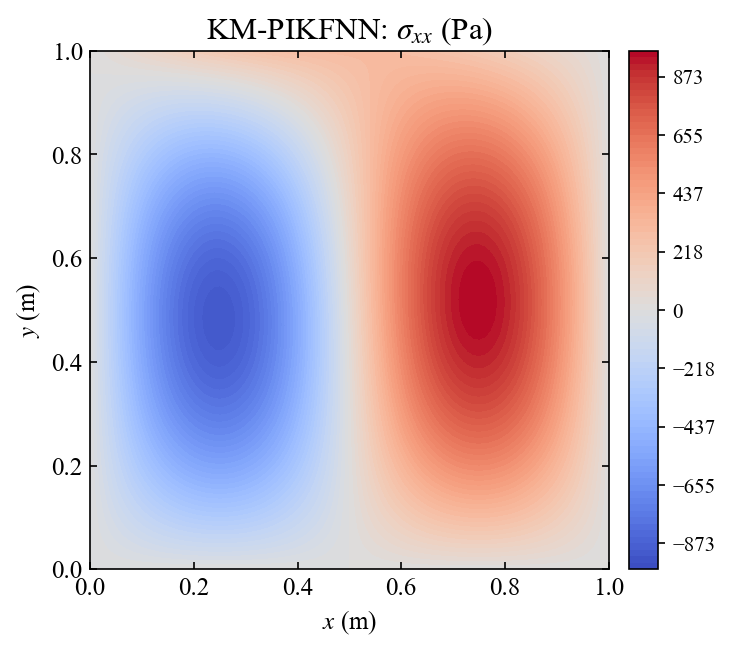

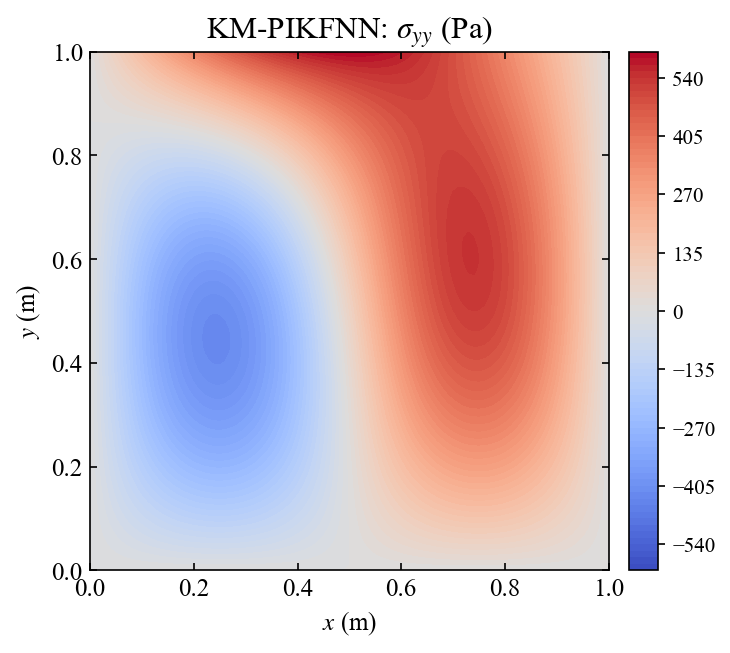

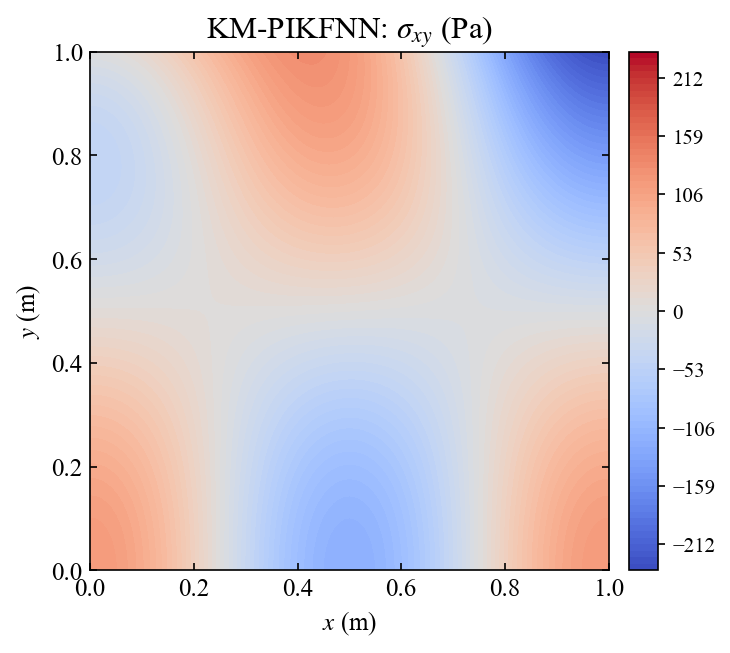

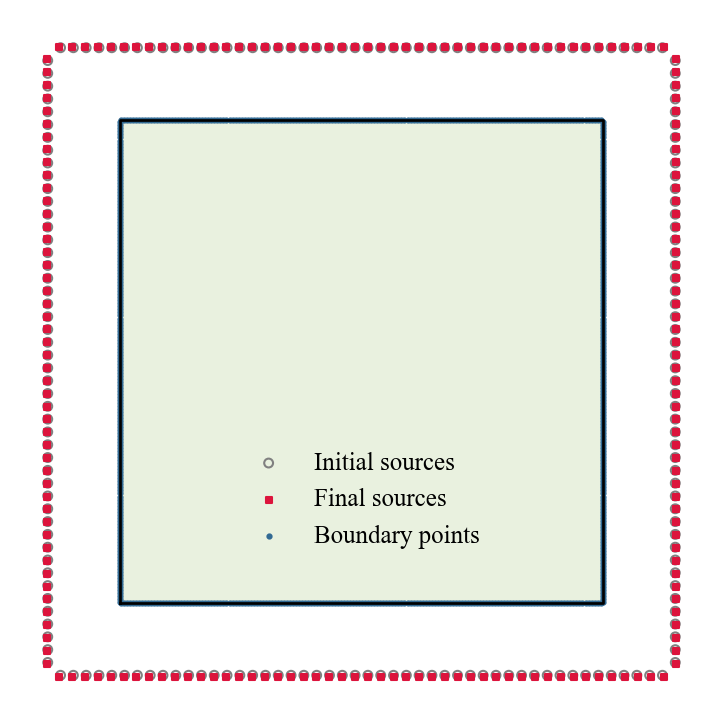

In [4]:
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'mathtext.fontset': 'stix', 'font.size': 12})
def savefig(fig, name):
    if cfg['save_outputs']:
        folder = Path(cfg['output_dir']); folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder/name, dpi=300, bbox_inches='tight')

# Ten standalone contour figures: five analytical, five KM-PIKFNN.
# Each exact/predicted pair shares the full range; do not clip stress extrema.
for kind,values in [('Analytical',reference_real),('KM-PIKFNN',prediction_real)]:
    for i,(name,label) in enumerate(zip(quantities,labels)):
        vmax=max(float(np.max(np.abs(reference_real[:,i]))),float(np.max(np.abs(prediction_real[:,i]))),1e-16)
        data=values[:,i].reshape(X.shape)
        fig,ax=plt.subplots(figsize=(5.4,4.8),dpi=150)
        fig.subplots_adjust(left=.16,right=.80,bottom=.14,top=.88)
        im=ax.contourf(L*X,L*Y,data,levels=np.linspace(-vmax,vmax,81),cmap='coolwarm',extend='both')
        ax.set_aspect('equal',adjustable='box')
        ax.set_xlabel(r'$x$ (m)');ax.set_ylabel(r'$y$ (m)')
        ax.set_title(f'{kind}: {label}',fontsize=15)
        ax.tick_params(direction='in',top=True,right=True)
        cax=ax.inset_axes([1.04,0,.055,1])
        cb=fig.colorbar(im,cax=cax,extendrect=True,extendfrac=0)
        cb.formatter.set_powerlimits((-3,3));cb.update_ticks();cb.ax.tick_params(labelsize=10)
        savefig(fig,f"{kind.replace('-','_').lower()}_{name}.png");plt.show()

# Initial and final source distributions.
fig, ax = plt.subplots(figsize=(6, 6), dpi=150)
ax.fill([0,L,L,0], [0,0,L,L], color='#CFE1B8', alpha=.45)
ax.plot([0,L,L,0,0], [0,0,L,L,0], 'k-', lw=1.3)
with torch.no_grad():
    initial_s = (0.5+0.5j)+best_run['alpha0']*model.base.cpu().numpy()
    final_s = model.sources().cpu().numpy()
ax.scatter(L*initial_s.real,L*initial_s.imag,s=18,facecolors='none',edgecolors='gray',label='Initial sources')
ax.scatter(L*final_s.real,L*final_s.imag,s=11,c='crimson',marker='s',label='Final sources')
bnd = np.concatenate([z.cpu().numpy() for z in train_points.values()])
ax.scatter(L*bnd.real,L*bnd.imag,s=4,c='#326A93',label='Boundary points')
ax.set_aspect('equal');ax.set_axis_off()
ax.legend(loc='center',bbox_to_anchor=(.5,.30),frameon=False,fontsize=12)
savefig(fig,'source_distribution.png');plt.show()

if cfg['save_outputs']:
    folder=Path(cfg['output_dir']);folder.mkdir(parents=True,exist_ok=True)
    for filename, rows in [('field_errors.csv',error_table),
             ('run_summary.csv',[dict(alpha_initial=r['alpha0'],alpha_final=r['model'].alpha().item(),
                  held_out_loss=r['check_loss'],elapsed_seconds=r['elapsed'],
                  initialization_seconds=r['initialization_time']) for r in runs])]:
        with (folder/filename).open('w',newline='',encoding='utf-8-sig') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    for run in runs:
        with (folder/f"history_alpha{run['alpha0']:.2f}.csv").open('w',newline='',encoding='utf-8-sig') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(run['history'][0]));writer.writeheader();writer.writerows(run['history'])
    np.savez(folder/'fields_and_coefficients.npz',X=L*X,Y=L*Y,
             prediction=prediction_real,reference=reference_real,quantities=np.array(quantities),
             coefficients=model.raw_coefficients().detach().cpu().numpy(),
             sources=L*final_s,alpha=model.alpha().item(),body_force=F_ref*body_force_fields(plot_z).detach().cpu().numpy())


## Four-start adaptive histories and fixed/adaptive/PINN table
The 2x2 figure contains all four starts in every panel. PINN fields/time are read from its saved NPZ/JSON; no PINN retraining occurs. Missing PINN results leave a 8-row KM table and can be added later by the standalone plotting script.


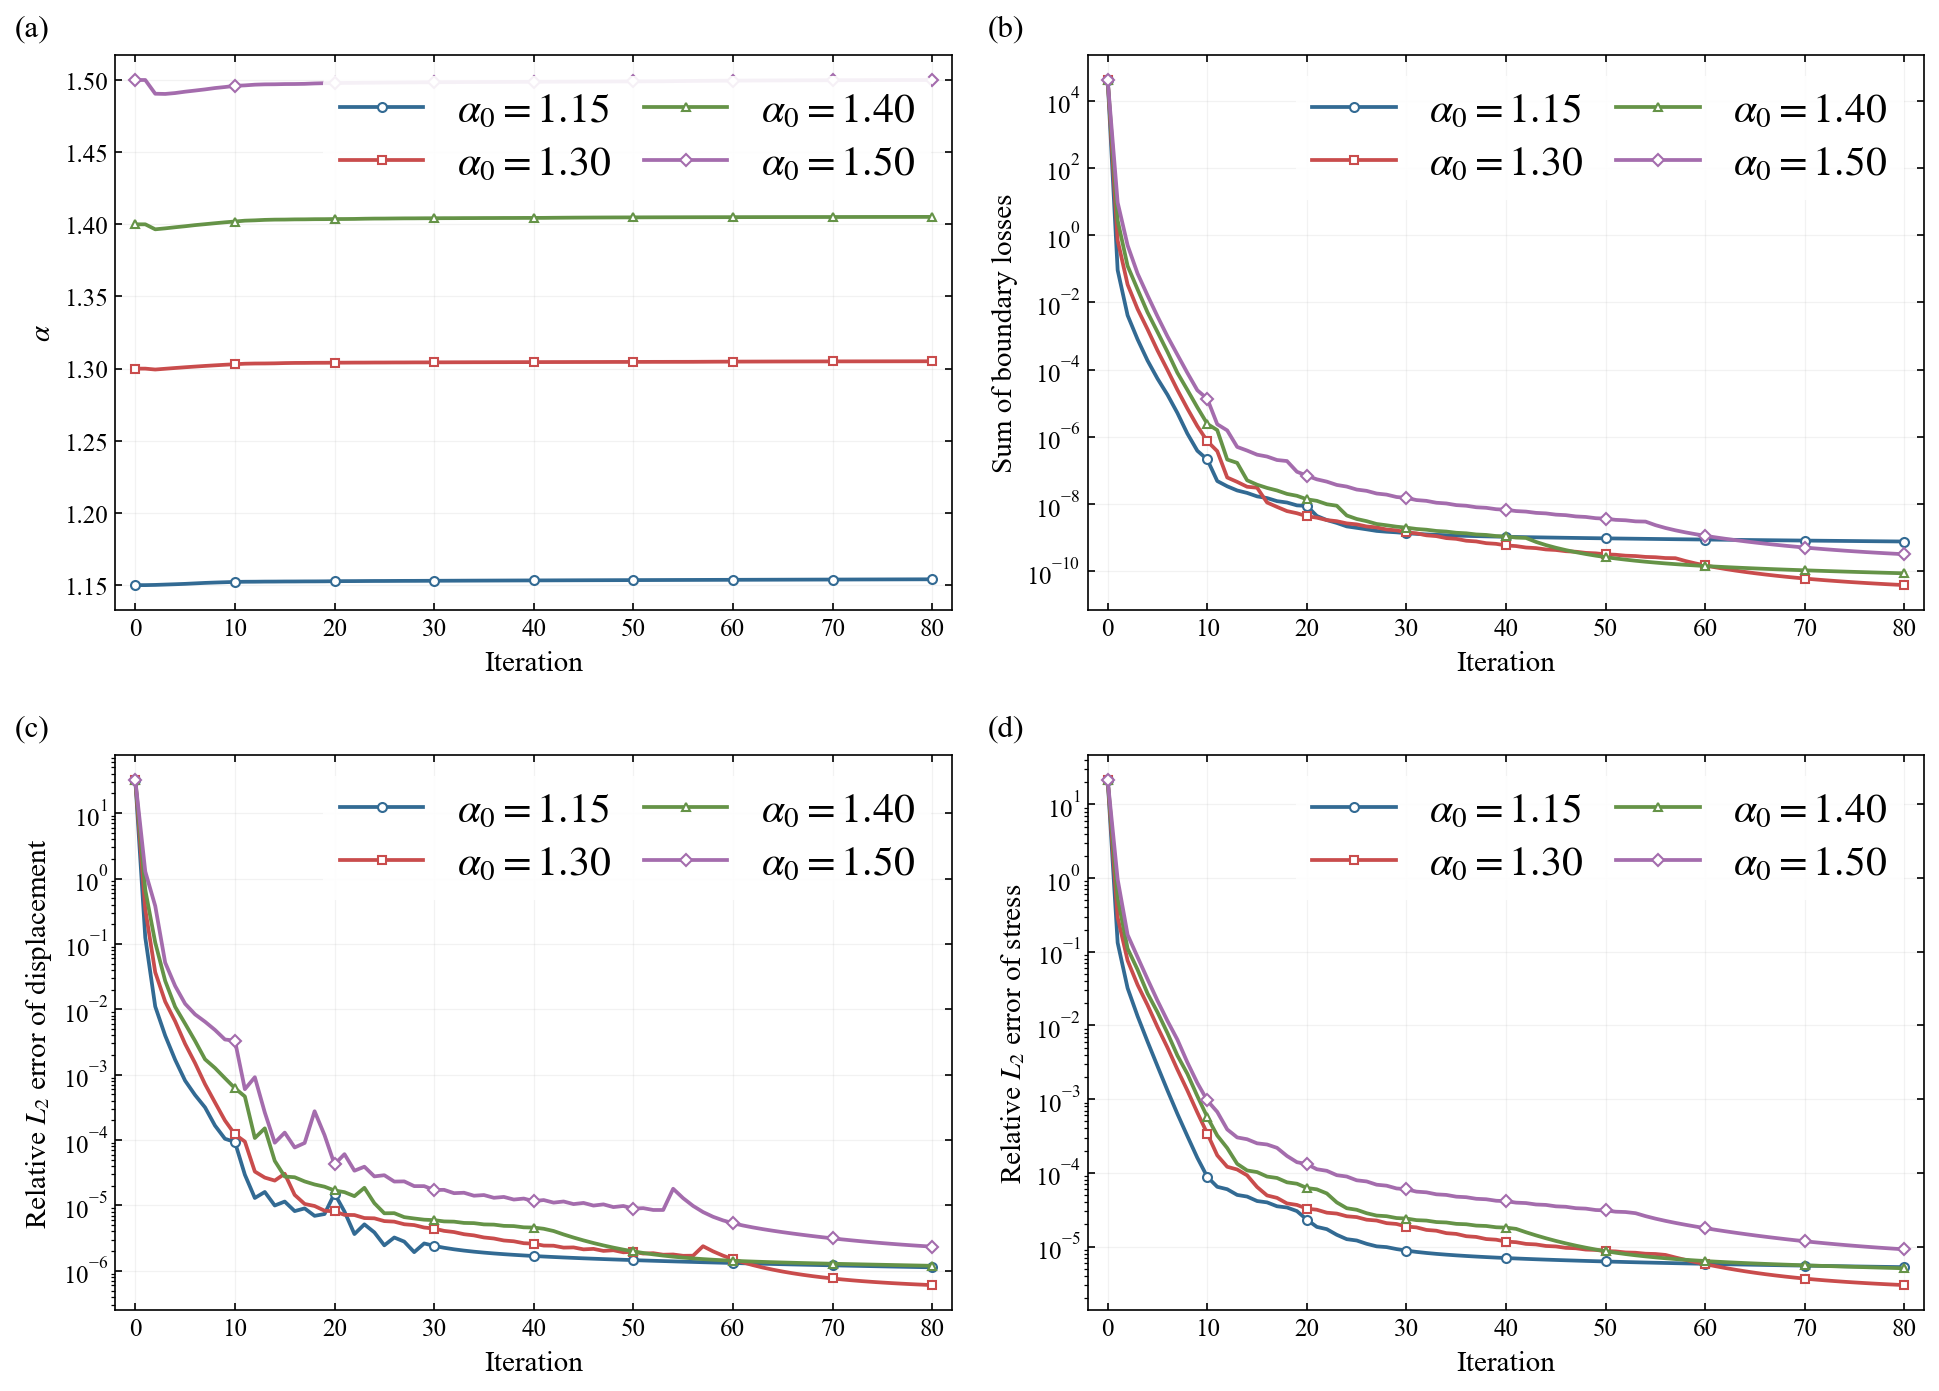

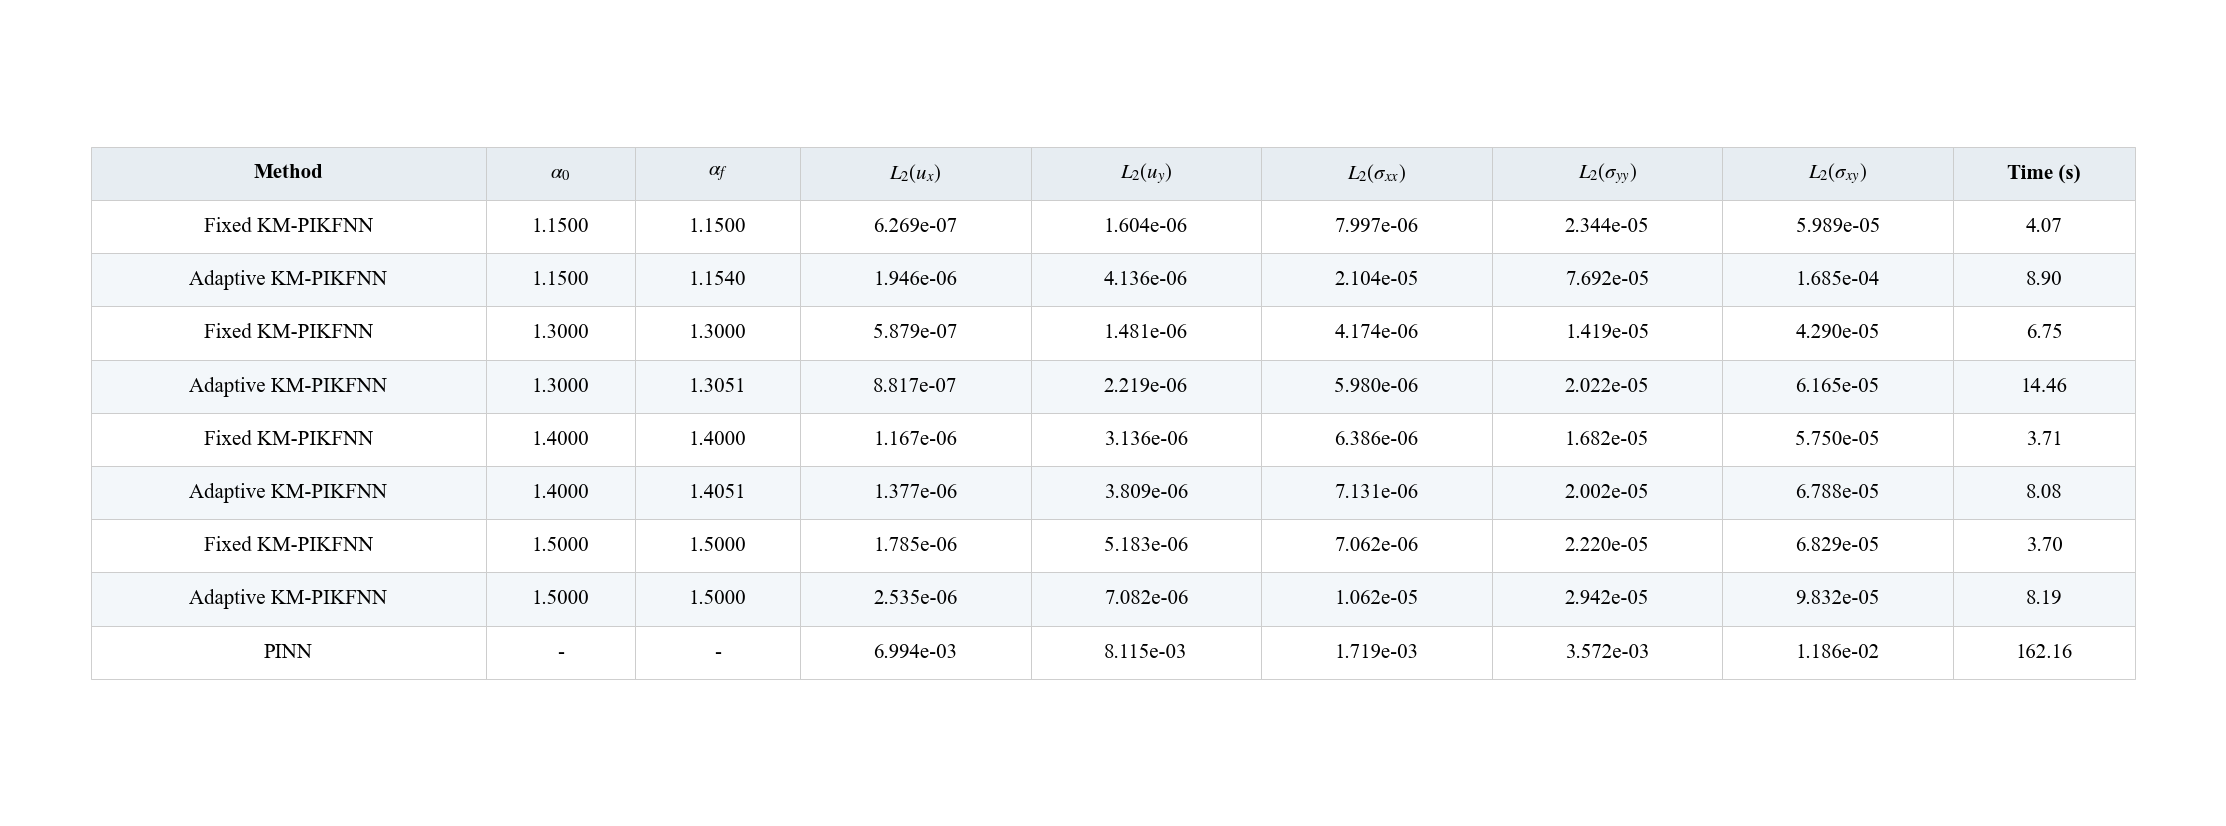

Saved 9 comparison rows and figures to: C:\Users\magic\Desktop\KM-PIKFNN\方板受压含体力\literature23_joint_LM_results


In [12]:
"""Replot four-start adaptive histories and compare saved KM / PINN fields.
Run this script after the sensitivity notebook and the PINN notebook.
Only NumPy and Matplotlib are required; no solver is rerun.
"""
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
CFG = dict(km_dir=BASE_DIR/'literature23_sensitivity_results',
           pinn_dir=BASE_DIR/'literature23_pinn_results',
           output_dir=BASE_DIR/'literature23_sensitivity_results',
           legend_fontsize=50, label_fontsize=20, dpi=400, show=True)
QUANTITIES = ('ux', 'uy', 'sxx', 'syy', 'sxy')
COLORS = ('#326A93', '#C94C4C', '#659347', '#A46CAD', '#D28B35', '#379E9A', '#5B5B5B')
MARKERS = ('o', 's', '^', 'D', 'v', 'P', 'X')

def read_csv(path):
    with Path(path).open(encoding='utf-8-sig', newline='') as stream:
        return list(csv.DictReader(stream))

def write_csv(path, rows):
    with Path(path).open('w', encoding='utf-8-sig', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

def load_fields(path):
    with np.load(path, allow_pickle=False) as data:
        names = [str(s) for s in data['quantities']]
        order = [names.index(q) for q in QUANTITIES]
        prediction = np.asarray(data['prediction']).reshape(-1, len(names))[:, order]
        reference = np.asarray(data['reference']).reshape(-1, len(names))[:, order]
        if not np.isfinite(prediction).all() or not np.isfinite(reference).all():
            raise ValueError(f'Nonfinite fields: {path}')
        result = dict(X=data['X'].copy(), Y=data['Y'].copy(), prediction=prediction,
                      reference=reference)
        if 'solver_elapsed_seconds' in data:
            result['time_seconds'] = float(data['solver_elapsed_seconds'])
    return result

def add_pinn_row(rows, km_dir, pinn_dir):
    path = pinn_dir/'fields_and_coefficients.npz'
    if not path.is_file():
        print(f'PINN data not found: {path.resolve()}')
        print('The 8 KM rows are saved. Run PINN once, then rerun this plotting script.')
        return rows
    km = load_fields(km_dir/'fields_and_coefficients.npz')
    pinn = load_fields(path)
    for key in ('X', 'Y', 'reference'):
        if km[key].shape != pinn[key].shape or not np.allclose(km[key], pinn[key], rtol=1e-10, atol=1e-12):
            raise ValueError(f'KM / PINN {key} mismatch: use the same grid, problem, and physical scales.')
    metadata_path = pinn_dir/'run_summary.json'
    metadata = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.is_file() else {}
    elapsed = pinn.get('time_seconds', metadata.get('solver_elapsed_seconds'))
    if elapsed is None:
        raise ValueError('PINN solver time is absent; do not substitute plotting time.')
    device = metadata.get('device', 'unknown')
    if device != 'unknown' and any(r['device'] != device for r in rows):
        print('WARNING: different devices in the timing comparison; the device column records this.')
    row = {key: '' for key in rows[0]}
    row.update(method='PINN', time_seconds=elapsed, device=device,
               parameter_count=metadata.get('parameter_count', ''),
               n_boundary=metadata.get('n_boundary', ''), n_interior=metadata.get('n_interior', ''),
               warm_start='False')
    errors = np.linalg.norm(pinn['prediction']-pinn['reference'], axis=0)/np.linalg.norm(pinn['reference'], axis=0)
    row.update({f'L2_{q}': float(e) for q, e in zip(QUANTITIES, errors)})
    return rows+[row]

def plot_histories(km_dir, output_dir, config):
    initials=config.get('alpha_initials')
    paths=([km_dir/f'history_adaptive_alpha{a:.2f}.csv' for a in initials]
           if initials is not None else sorted(km_dir.glob('history_adaptive_alpha*.csv')))
    missing=[str(p) for p in paths if not p.is_file()]
    if missing: raise FileNotFoundError('Missing selected histories: '+', '.join(missing))
    if not paths:
        raise FileNotFoundError(f'No adaptive histories in {km_dir.resolve()}')
    panels = [('alpha', r'$\alpha$'), ('boundary_loss', 'Sum of boundary losses'),
              ('displacement_L2', r'Relative $L_2$ error of displacement'),
              ('stress_L2', r'Relative $L_2$ error of stress')]
    fig, axes = plt.subplots(2, 2, figsize=(13.2, 9.6), dpi=150)
    for panel_index, (ax, (key, label)) in enumerate(zip(axes.ravel(), panels)):
        for j, path in enumerate(paths):
            history = read_csv(path)
            initial = float(path.stem.split('alpha')[-1])
            x = [float(r['iteration']) for r in history]
            y = [float(r[key]) for r in history]
            if key != 'alpha':
                y = np.maximum(y, 1e-30)
            ax.plot(x, y, color=COLORS[j % len(COLORS)], marker=MARKERS[j % len(MARKERS)],
                    markevery=max(1, len(x)//8), ms=4.3, lw=1.8, markerfacecolor='white',
                    label=rf'$\alpha_0={initial:.2f}$')
        if key != 'alpha':
            ax.set_yscale('log')
        ax.set_xlabel('Iteration', fontsize=config['label_fontsize'])
        ax.set_ylabel(label, fontsize=config['label_fontsize'])
        ax.tick_params(direction='in', top=True, right=True)
        ax.grid(alpha=.16, lw=.6)
        ax.margins(x=.025)
        placement = dict(loc='best')
        ax.legend(**placement, ncol=2, fontsize=config['legend_fontsize'],
                  frameon=True, framealpha=.9, facecolor='white', edgecolor='none',
                  handlelength=2, columnspacing=.8, labelspacing=.35)
        ax.text(-.12, 1.035, f'({chr(97+panel_index)})', transform=ax.transAxes, fontsize=15)
    fig.tight_layout(pad=1.6)
    for ext in ('png', 'pdf'):
        fig.savefig(output_dir/f'adaptive_four_initializations_2x2.{ext}', dpi=config['dpi'], bbox_inches='tight')
    if config['show']: plt.show()
    else: plt.close(fig)

def render_table(rows, output_dir, config):
    columns = ['Method', r'$\alpha_0$', r'$\alpha_f$', r'$L_2(u_x)$', r'$L_2(u_y)$',
               r'$L_2(\sigma_{xx})$', r'$L_2(\sigma_{yy})$', r'$L_2(\sigma_{xy})$', 'Time (s)']
    entries = []
    md = ['| Method | alpha0 | alpha_final | L2(ux) | L2(uy) | L2(sxx) | L2(syy) | L2(sxy) | Time (s) |',
          '|---|---:|---:|---:|---:|---:|---:|---:|---:|']
    for row in rows:
        entry = [row['method'], *(f'{float(row[k]):.4f}' if str(row[k]) else '-' for k in ('alpha_initial','alpha_final')),
                 *(f'{float(row[f"L2_{q}"]):.3e}' for q in QUANTITIES), f'{float(row["time_seconds"]):.2f}']
        entries.append(entry); md.append('| '+' | '.join(entry)+' |')
    note = ('Relative L2 errors are computed componentwise on the same evaluation grid. '
            'Time is per run and includes initialization, training, and in-training diagnostics; '
            'field export and plotting are excluded. KM times include basis assembly and rank-revealing QR; all coefficients start at zero. '
            'Four-start total search costs are reported separately in search_costs.csv. '
            'See CSV device and parameter columns before comparing timings.')
    (output_dir/'method_comparison_table.md').write_text('\n'.join(md)+'\n\n'+note+'\n', encoding='utf-8')
    fig, ax = plt.subplots(figsize=(15, .43*len(rows)+1.8), dpi=150)
    ax.axis('off')
    table = ax.table(cellText=entries, colLabels=columns, loc='center', cellLoc='center',
                     colWidths=[.18,.068,.075,.105,.105,.105,.105,.105,.083])
    table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1,1.75)
    for (i,j), cell in table.get_celld().items():
        cell.set_edgecolor('#CCCCCC'); cell.set_linewidth(.45)
        if i == 0:
            cell.set_facecolor('#E7EDF2'); cell.set_text_props(weight='bold')
        elif entries[i-1][0].startswith('Adaptive'):
            cell.set_facecolor('#F3F7FA')
    fig.tight_layout()
    for ext in ('png','pdf'):
        fig.savefig(output_dir/f'method_comparison_table.{ext}', dpi=config['dpi'], bbox_inches='tight')
    if config['show']: plt.show()
    else: plt.close(fig)

def make_comparison(config=None):
    config = CFG if config is None else config
    km_dir, pinn_dir, output_dir = (Path(config[k]).expanduser() for k in ('km_dir','pinn_dir','output_dir'))
    output_dir.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({'font.family':'serif', 'font.serif':['Times New Roman','DejaVu Serif'],
                         'mathtext.fontset':'stix', 'font.size':12})
    rows = read_csv(km_dir/'per_run_metrics.csv')
    rows = add_pinn_row(rows, km_dir, pinn_dir)
    write_csv(output_dir/'method_comparison.csv', rows)
    plot_histories(km_dir, output_dir, config)
    render_table(rows, output_dir, config)
    print(f'Saved {len(rows)} comparison rows and figures to: {output_dir.resolve()}')
    return rows


# Change only this directory if your existing PINN results are elsewhere.
if cfg['save_outputs']:
    comparison_rows = make_comparison(dict(km_dir=Path(cfg['output_dir']),
        pinn_dir=Path(cfg['pinn_output_dir']), output_dir=Path(cfg['output_dir']),
        alpha_initials=cfg['alpha_initials'], legend_fontsize=20,
        label_fontsize=cfg['label_fontsize'], dpi=400, show=True))
else:
    print('Enable cfg["save_outputs"] to create the comparison table and four-panel figure.')


## CPU verification

The three retained configurations were verified in the preceding four-pair run. The replacement adaptive initial value 1.40 was tested separately with the same 80-step settings; its final source scale is 1.40514418. GPU execution remains unverified.

| alpha0 | ux L2 | uy L2 | sxx L2 | syy L2 | sxy L2 |
|---|---:|---:|---:|---:|---:|
| 1.15 | 1.9455e-06 | 4.1364e-06 | 2.1041e-05 | 7.6921e-05 | 1.6846e-04 |
| 1.30 | 8.8172e-07 | 2.2190e-06 | 5.9803e-06 | 2.0223e-05 | 6.1646e-05 |
| 1.40 | 1.3772e-06 | 3.8085e-06 | 7.1314e-06 | 2.0017e-05 | 6.7880e-05 |
| 1.50 | 2.5350e-06 | 7.0823e-06 | 1.0623e-05 | 2.9421e-05 | 9.8323e-05 |
